# Ice-Maker: прогноз попиту та місток до оптимізації

Продажі портативного льодогенератора на Amazon, 2017–2020.

**План**
1. Дослідження та очищення даних: характеристики ряду, аномалії та пропуски, агрегація
2. Схема валідації: горизонт, бектест, витоки
3. Базові моделі та метрики
4. Місток до оптимізації: постановка задачі та поточні обмеження
5. Висновки та наступні кроки

*Код згорнутий; повний аналіз у `eda.ipynb`.*

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.holtwinters import ExponentialSmoothing

NAVY, BLUE, ORANGE, GREY, RED, GREEN = "#24476B", "#5686B5", "#E07B39", "#7A8A99", "#B03A2E", "#2F855A"
plt.rcParams.update({
    "figure.figsize": (13, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
    "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False,
})

# ---------- sales
sales = pd.read_excel("sales.xlsx")
sales["date"] = pd.to_datetime(sales["Unnamed: 0"])
daily = sales.drop(columns=["Unnamed: 0"]).set_index("date").sort_index()
tgt = daily["target"]
kw_cols = [c for c in daily.columns if c not in ["target", "inventory_fbm", "inventory_fba"]]

FIRST_SALE = tgt[tgt > 0].index[0]
LAST_VALID = tgt.last_valid_index()
MODEL_START, MODEL_END = pd.Timestamp("2017-11-01"), pd.Timestamp("2019-12-20")
ts = tgt.loc[MODEL_START:MODEL_END].asfreq("D")
ls = np.log1p(ts)

# ---------- orders
orders = pd.read_excel("orders.xlsx")
orders = orders.loc[:, ~orders.columns.str.contains("^Unnamed")]
orders["date"] = pd.to_datetime(orders["date"])
orders_daily = orders.groupby("date").agg(order_rows=("count", "size"), order_units=("count", "sum"))

# ---------- competitors -> own price = competitor price / ratio
comp = pd.read_excel("competitors.xlsx").rename(columns={"Unnamed: 0": "date"})
comp["date"] = pd.to_datetime(comp["date"])
comp = comp.set_index("date")
price_cols = [c for c in comp.columns if c.endswith("_competitorPrice")]
ratio_cols = [c for c in comp.columns if c.endswith("_competitorRatio")]
inferred = pd.DataFrame({r: (comp[r.replace("_competitorRatio", "_competitorPrice")] / comp[r])
                         .where((comp[r] > 0) & (comp[r.replace("_competitorRatio", "_competitorPrice")] > 0))
                         for r in ratio_cols})
own_price_raw = inferred.median(axis=1)
PRICE_LAST_REAL = pd.Timestamp("2019-12-01")
own_price = own_price_raw.where(own_price_raw.index <= PRICE_LAST_REAL)

# ---------- anomalies: robust z of log(1+y) vs 29-day centred median, weekday-adjusted
local_median = ls.rolling(29, center=True, min_periods=15).median()
dev = ls - local_median
dev = dev - dev.groupby(dev.index.dayofweek).transform("median")
robust_z = (dev - dev.median()) / (1.4826 * (dev - dev.median()).abs().median())
flag = robust_z.abs() > 3.5
events = {"2017-11-24": "BF", "2017-11-27": "CM", "2018-11-23": "BF", "2018-11-26": "CM",
          "2019-11-29": "BF", "2019-12-02": "CM", "2018-07-16": "Prime", "2018-07-17": "Prime",
          "2019-07-15": "Prime", "2019-07-16": "Prime"}
event_days = [pd.Timestamp(d) for d in events]
near_event = pd.Series([any(abs((d - e).days) <= 1 for e in event_days) for d in ts.index], index=ts.index)
fba = daily["inventory_fba"].reindex(ts.index)

# ---------- keyword tracking window
ranked = (daily[kw_cols] > 0).sum(axis=1)
TRACK_START, TRACK_END = ranked[ranked > 0].index[[0, -1]]

# ---------- weekly aggregation (full weeks only)
wk = ts.resample("W-SUN").agg(["sum", "size"])
weekly = wk.loc[wk["size"] == 7, "sum"]
print("Дані завантажено:", f"{len(daily)} днів у sales, {len(orders):,} замовлень, {len(comp)} тижнів цін")

Дані завантажено: 1191 днів у sales, 89,934 замовлень, 204 тижнів цін


# 1. Дослідження та очищення даних

### Що є в даних

| Файл | Що всередині | Розмір |
|---|---|---|
| `sales.xlsx` | денний `target`, залишки FBA/FBM (0–1), позиції за 50 пошуковими запитами | 1 191 день, 27.09.2017 – 30.12.2020 |
| `orders.xlsx` | кожне замовлення: дата, кількість штук, координати покупця, склад | 89 934 замовлення, 7 складів |
| `competitors.xlsx` | ціни 9 конкурентів і відношення до нашої ціни | 204 тижні |

## 1.1 Життєвий цикл товару і робоче вікно

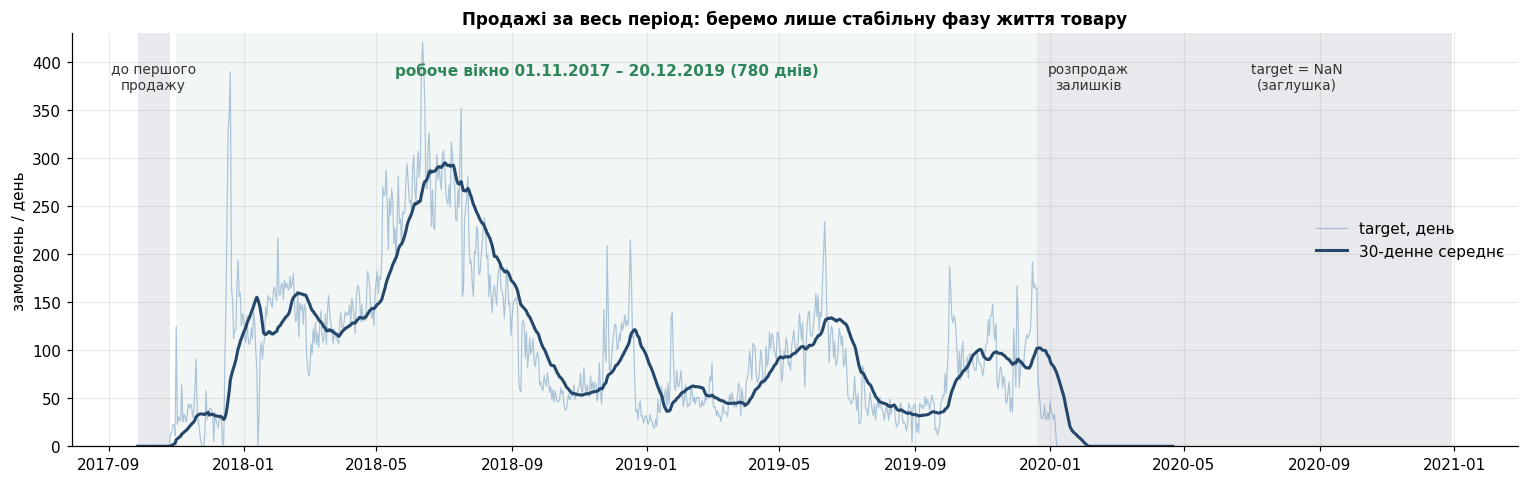

У робочому вікні 780 днів і 85,738 продажів (99.2% від усіх); нульових днів усередині: 2


In [2]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(tgt.index, tgt, color=BLUE, alpha=0.45, linewidth=0.8, label="target, день")
ax.plot(tgt.index, tgt.rolling(30, min_periods=1).mean(), color=NAVY, linewidth=2, label="30-денне середнє")
spans = [(tgt.index[0], FIRST_SALE, "до першого\nпродажу"),
         (MODEL_END, LAST_VALID, "розпродаж\nзалишків"),
         (LAST_VALID, tgt.index[-1], "target = NaN\n(заглушка)")]
for a, b, label in spans:
    ax.axvspan(a, b, color=GREY, alpha=0.18, linewidth=0)
    ax.text(a + (b - a) / 2, 400, label, ha="center", va="top", fontsize=9, color="#333")
ax.axvspan(MODEL_START, MODEL_END, color=GREEN, alpha=0.06, linewidth=0)
ax.text(MODEL_START + (MODEL_END - MODEL_START) / 2, 400,
        "робоче вікно 01.11.2017 – 20.12.2019 (780 днів)", ha="center", va="top", fontsize=10, color=GREEN, fontweight="bold")
ax.set_ylim(0, 430)
ax.set_ylabel("замовлень / день")
ax.set_title("Продажі за весь період: беремо лише стабільну фазу життя товару")
ax.legend(loc="center right")
plt.tight_layout(); plt.show()

share = ts.sum() / tgt.sum()
print(f"У робочому вікні {len(ts)} днів і {ts.sum():,.0f} продажів ({share:.1%} від усіх); нульових днів усередині: {int((ts == 0).sum())}")

- Перший продаж **26.10.2017**, останній **06.01.2020**.
- З **21.12.2019** продажі падають зі ~165 до ~30/день при порожньому FBA → це розпродаж залишків, а не попит.
- З **24.03.2020** `target = NaN` рівно тоді, коли обидва inventory = 1.0 → заглушка, а не нульовий попит.
- **Робоче вікно: 780 днів, 99,2% усіх продажів.**

## 1.2 Характеристики часового ряду

In [3]:
dec = seasonal_decompose(ls, model="additive", period=7, extrapolate_trend="freq")
s_trend = max(0, 1 - dec.resid.var() / (dec.resid + dec.trend).var())
s_week = max(0, 1 - dec.resid.var() / (dec.resid + dec.seasonal).var())
rel = (ts / ts.rolling(7, center=True).mean()).dropna()
kw_p = stats.kruskal(*[rel[rel.index.dayofweek == d] for d in range(7)]).pvalue

def stat_verdict(x):
    adf_p = adfuller(x, autolag="AIC")[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_p = kpss(x, regression="c", nlags="auto")[1]
    v = "стаціонарний" if adf_p < .05 and kpss_p > .05 else ("нестаціонарний" if adf_p >= .05 and kpss_p <= .05 else "суперечливо (тренд/зсуви)")
    return f"ADF p={adf_p:.3f}, KPSS p={kpss_p:.2f} → {v}"

month_sum = ts.resample("MS").sum()
profile = pd.DataFrame({y: (month_sum[month_sum.index.year == y] / month_sum[month_sum.index.year == y].sum() * 100).values
                        for y in (2018, 2019)}, index=range(1, 13))
yr = ts.groupby(ts.index.year).mean()

table = pd.DataFrame({"значення": {
    "Середнє / медіана, замовлень на день": f"{ts.mean():.1f} / {ts.median():.0f}",
    "Коефіцієнт варіації": f"{ts.std() / ts.mean():.2f}",
    "Середнє 2018 → 2019": f"{yr[2018]:.1f} → {yr[2019]:.1f}  (≈ −51%)",
    "Асиметрія: сирий / log(1+y)": f"{stats.skew(ts):.2f} / {stats.skew(ls):.2f}",
    "Сила тренду (0..1)": f"{s_trend:.2f}",
    "Сила тижневої сезонності (0..1)": f"{s_week:.2f}  (але значуща: Kruskal–Wallis p = {kw_p:.1e})",
    "Кореляція річних профілів 2018 / 2019": f"{profile[2018].corr(profile[2019]):.2f}",
    "Стаціонарність log(1+y)": stat_verdict(ls),
    "Стаціонарність diff(1)": stat_verdict(ls.diff().dropna()),
}})
display(table)

,значення
"Середнє / медіана, замовлень на день",109.9 / 96
Коефіцієнт варіації,0.68
Середнє 2018 → 2019,150.8 → 73.8 (≈ −51%)
Асиметрія: сирий / log(1+y),1.16 / -1.10
Сила тренду (0..1),0.86
Сила тижневої сезонності (0..1),0.06 (але значуща: Kruskal–Wallis p = 7.4e-24)
Кореляція річних профілів 2018 / 2019,0.23
Стаціонарність log(1+y),"ADF p=0.026, KPSS p=0.01 → суперечливо (тренд/..."
Стаціонарність diff(1),"ADF p=0.000, KPSS p=0.10 → стаціонарний"


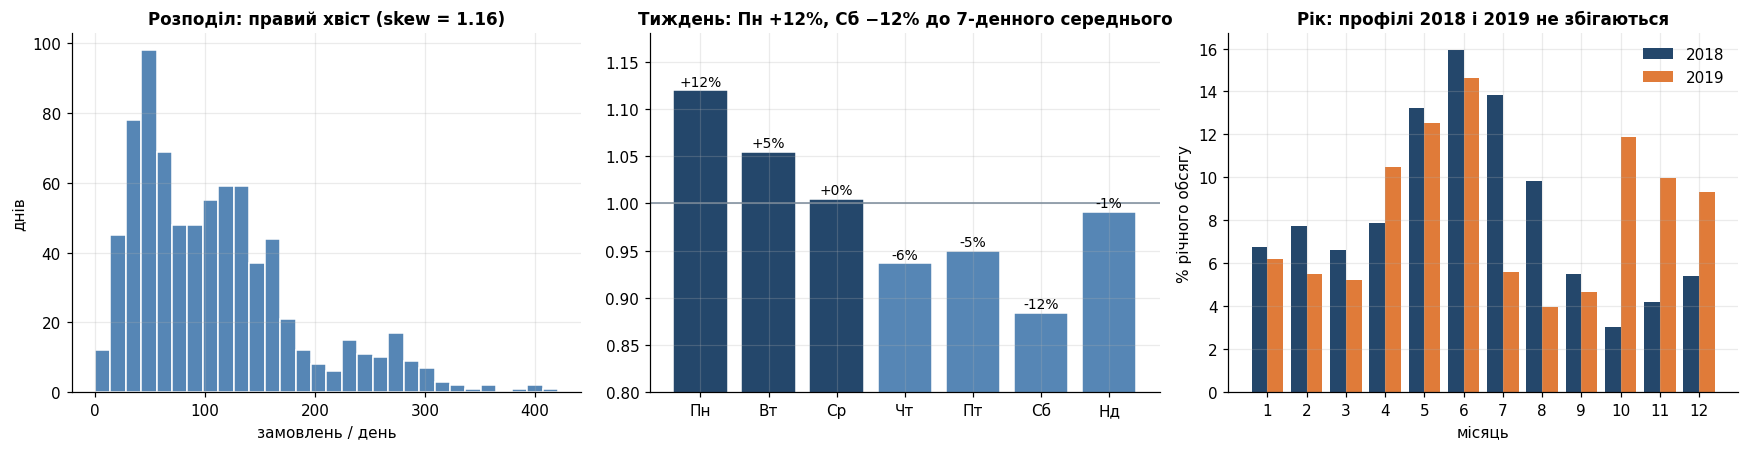

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

axes[0].hist(ts, bins=30, color=BLUE, edgecolor="white")
axes[0].set_title(f"Розподіл: правий хвіст (skew = {stats.skew(ts):.2f})")
axes[0].set_xlabel("замовлень / день"); axes[0].set_ylabel("днів")

dow = rel.groupby(rel.index.dayofweek).mean()
names = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Нд"]
bars = axes[1].bar(names, dow.values, color=[NAVY if v > 1 else BLUE for v in dow.values], edgecolor="white")
axes[1].axhline(1, color=GREY, linewidth=1)
axes[1].set_ylim(0.8, 1.18)
for b, v in zip(bars, dow.values):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 0.005, f"{(v - 1) * 100:+.0f}%", ha="center", fontsize=9)
axes[1].set_title("Тиждень: Пн +12%, Сб −12% до 7-денного середнього")

x = np.arange(1, 13)
axes[2].bar(x - 0.2, profile[2018], width=0.4, color=NAVY, label="2018")
axes[2].bar(x + 0.2, profile[2019], width=0.4, color=ORANGE, label="2019")
axes[2].set_xticks(x)
axes[2].set_xlabel("місяць"); axes[2].set_ylabel("% річного обсягу")
axes[2].set_title("Рік: профілі 2018 і 2019 не збігаються")
axes[2].legend()
plt.tight_layout(); plt.show()

**Висновки**
- **Тренд домінує** (сила 0,86): ряд з великою інерцією, продажі 2019 вдвічі нижчі за 2018.
- **Тижнева сезонність слабка, але стабільна**: Пн +12%, Сб −12%, однаково у 2018 і 2019 → дамі за днем тижня / сезонний період 7.
- **Річна сезонність нестійка** (кореляція профілів 0,23): у 2019 липень–серпень обвалились, а жовтень–грудень зросли — це радше наявність товару, ніж календар.
- Розкид росте з рівнем → **log(1+y)** для ETS/ARIMA; після **diff(1)** ряд стаціонарний → d = 1.

## 1.3 Аномалії

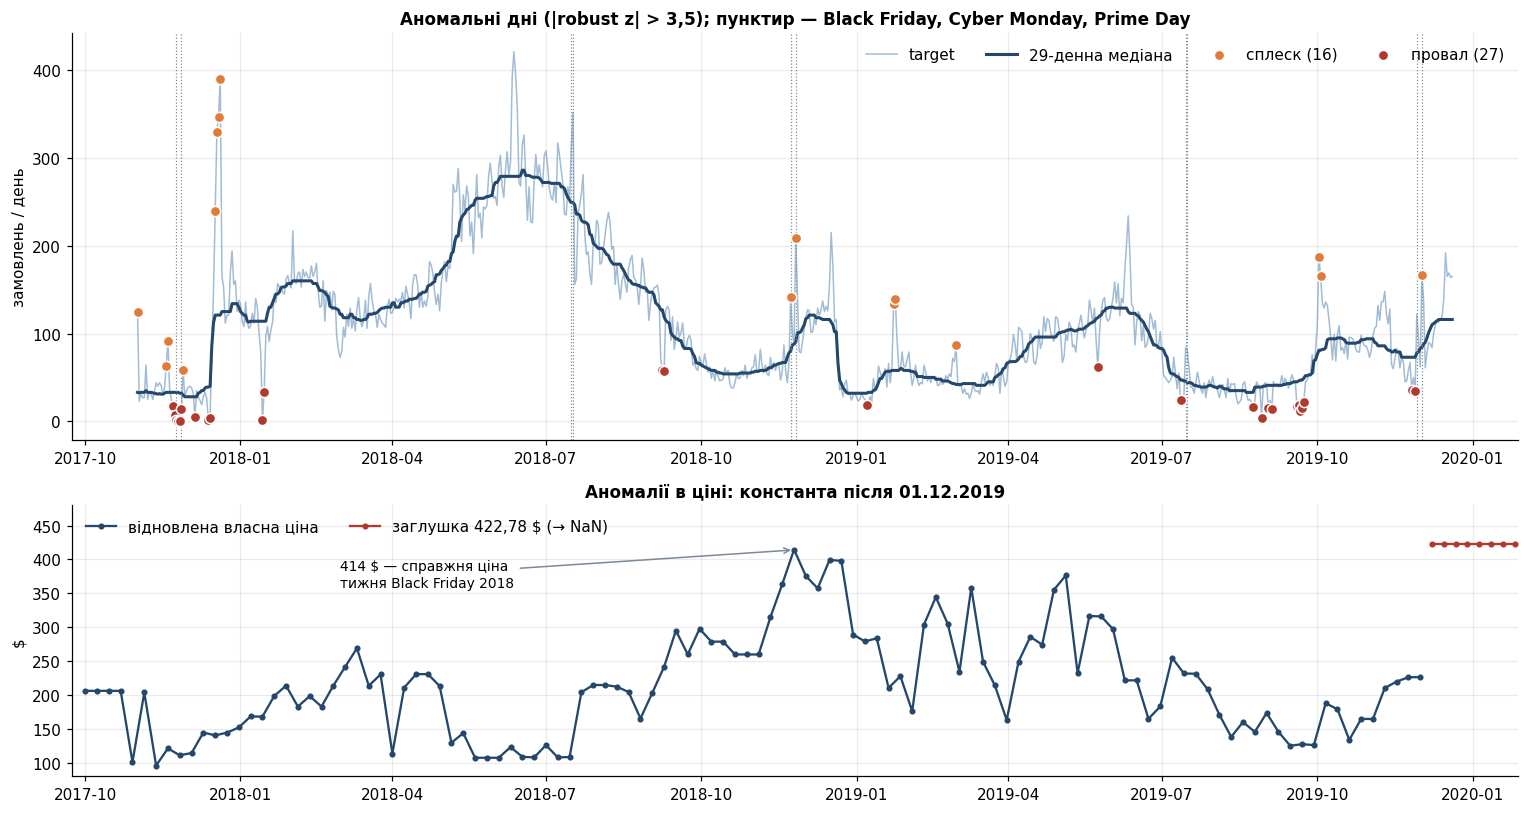

,днів,з них FBA = 0,біля події ±1 день
провали,27,85%,22%
сплески,16,50%,25%


Для порівняння: FBA = 0 у 41% усіх днів вікна


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), gridspec_kw={"height_ratios": [3, 2]})
ax = axes[0]
ax.plot(ts.index, ts, color=BLUE, alpha=0.55, linewidth=1, label="target")
ax.plot(np.expm1(local_median), color=NAVY, linewidth=2, label="29-денна медіана")
up, down = flag & (robust_z > 0), flag & (robust_z < 0)
ax.scatter(ts.index[up], ts[up], s=45, color=ORANGE, edgecolor="white", zorder=3, label=f"сплеск ({int(up.sum())})")
ax.scatter(ts.index[down], ts[down], s=45, color=RED, edgecolor="white", zorder=3, label=f"провал ({int(down.sum())})")
for d in event_days:
    ax.axvline(d, color=GREY, linewidth=0.8, linestyle=":")
ax.set_ylabel("замовлень / день")
ax.set_title("Аномальні дні (|robust z| > 3,5); пунктир — Black Friday, Cyber Monday, Prime Day")
ax.legend(ncol=4, loc="upper right")

ax = axes[1]
p = own_price_raw.loc[:"2020-03-22"]
real, fake = p[p.index <= PRICE_LAST_REAL], p[p.index > PRICE_LAST_REAL]
ax.plot(real.index, real, color=NAVY, marker="o", markersize=3, linewidth=1.5, label="відновлена власна ціна")
ax.plot(fake.index, fake, color=RED, marker="o", markersize=3, linewidth=1.5, label="заглушка 422,78 $ (→ NaN)")
ax.annotate("414 $ — справжня ціна\nтижня Black Friday 2018", xy=(pd.Timestamp("2018-11-25"), 414),
            xytext=(pd.Timestamp("2018-03-01"), 360), arrowprops=dict(arrowstyle="->", color=GREY), fontsize=9)
ax.set_ylim(80, 480)
ax.set_ylabel("$"); ax.set_title("Аномалії в ціні: константа після 01.12.2019")
ax.legend(loc="upper left", ncol=2)
ax.set_xlim(axes[0].get_xlim())
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    "днів": [int(down.sum()), int(up.sum())],
    "з них FBA = 0": [f"{(fba[down] == 0).mean():.0%}", f"{(fba[up] == 0).mean():.0%}"],
    "біля події ±1 день": [f"{near_event[down].mean():.0%}", f"{near_event[up].mean():.0%}"],
}, index=["провали", "сплески"])
display(summary)
print(f"Для порівняння: FBA = 0 у {(fba == 0).mean():.0%} усіх днів вікна")

- Знайдено **43 аномальні дні з 780**: 27 провалів і 16 сплесків.
- **Провали = відсутність товару**: 85% з них у дні з порожнім FBA (у середньому таких днів 41%). Напр., Black Friday 2017: 18, 7, 2, 0, 0 продажів.
- **Сплески = свята й акції**: перед Різдвом 2017 (до 390/день), BF/CM 2018–2019.
- **Ціна**: 422,78 $ після 01.12.2019 — заглушка → NaN.
- **Рішення: аномалії не видаляємо** (це реальні продажі), а позначаємо прапорами `is_anomaly`, `near_event`. Провали через порожній склад — цензурований попит.

## 1.4 Пропуски, нулі та заглушки

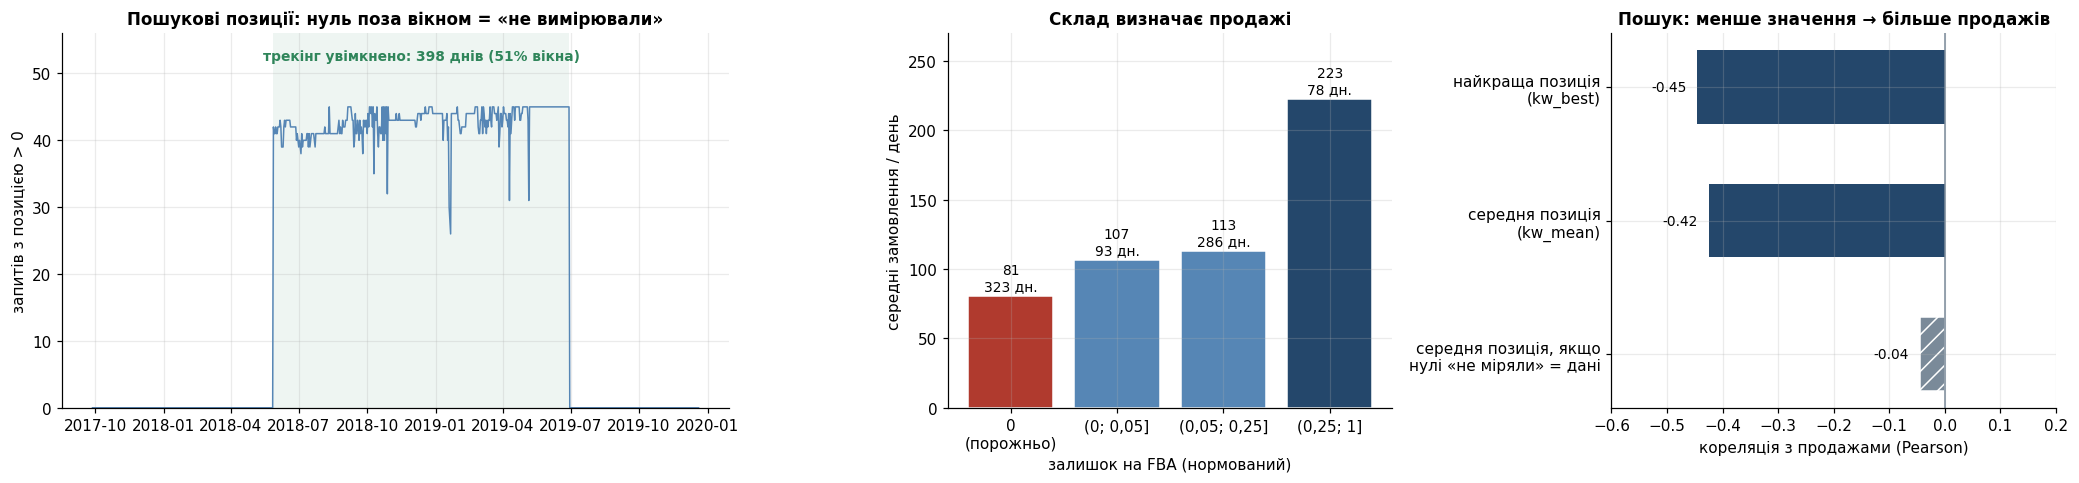

Що,Проблема,Рішення
target,282 дні NaN після 23.03.2020 (= inventory 1.0),відрізаємо (поза вікном)
позиції пошукових запитів,нулі поза 28.05.2018 – 29.06.2019; 5 колонок завжди 0,NaN + прапор kw_tracked; 5 колонок видаляємо
власна ціна,"до запуску (лют–вер 2017) ціни немає; з 08.12.2019 заглушка 422,78 $",останні 12 днів вікна — ціна 01.12.2019 (226 $) + прапор price_imputed
inventory_fba = 0,41% днів вікна,"це не пропуск, а цензурований попит"


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5), gridspec_kw={"width_ratios": [2.4, 1.6, 1.6]})

ax = axes[0]
r = ranked.loc[:MODEL_END]
ax.plot(r.index, r, color=BLUE, linewidth=1)
ax.axvspan(TRACK_START, TRACK_END, color=GREEN, alpha=0.08, linewidth=0)
ax.text(TRACK_START + (TRACK_END - TRACK_START) / 2, 52, "трекінг увімкнено: 398 днів (51% вікна)",
        ha="center", color=GREEN, fontweight="bold", fontsize=9)
ax.set_ylim(0, 56)
ax.set_ylabel("запитів з позицією > 0")
ax.set_title("Пошукові позиції: нуль поза вікном = «не вимірювали»")

ax = axes[1]
groups = pd.cut(fba, bins=[-0.001, 0, 0.05, 0.25, 1], labels=["0\n(порожньо)", "(0; 0,05]", "(0,05; 0,25]", "(0,25; 1]"])
g = ts.groupby(groups, observed=True).agg(["mean", "size"])
bars = ax.bar(g.index.astype(str), g["mean"], color=[RED, BLUE, BLUE, NAVY], edgecolor="white")
for b, (m, n) in zip(bars, g.values):
    ax.text(b.get_x() + b.get_width() / 2, m + 4, f"{m:.0f}\n{int(n)} дн.", ha="center", fontsize=9)
ax.set_ylim(0, 270)
ax.set_xlabel("залишок на FBA (нормований)"); ax.set_ylabel("середні замовлення / день")
ax.set_title("Склад визначає продажі")

# keyword positions vs sales: only on tracked days (smaller position number = higher in search)
ax = axes[2]
kw = daily.loc[MODEL_START:MODEL_END, kw_cols]
pos = kw.where(kw > 0)
on = (kw.index >= TRACK_START) & (kw.index <= TRACK_END)
y = ts.values
corr = {
    "найкраща позиція\n(kw_best)": pd.Series(y[on]).corr(pd.Series(pos.min(axis=1).values[on])),
    "середня позиція\n(kw_mean)": pd.Series(y[on]).corr(pd.Series(pos.mean(axis=1).values[on])),
    # mistake: untracked days (zeros) treated as real values over the whole window
    "середня позиція, якщо\nнулі «не міряли» = дані": pd.Series(y).corr(pd.Series(pos.mean(axis=1).fillna(0).values)),
}
vals = list(corr.values())
bars = ax.barh(list(corr), vals, color=[NAVY, NAVY, GREY], height=0.55)
bars[-1].set_hatch("//"); bars[-1].set_edgecolor("white")
for b, v in zip(bars, vals):
    ax.text(v + (0.02 if v > 0 else -0.02), b.get_y() + b.get_height() / 2, f"{v:+.2f}",
            va="center", ha="left" if v > 0 else "right", fontsize=9)
ax.axvline(0, color=GREY, linewidth=1)
ax.set_xlim(-0.6, 0.2); ax.invert_yaxis()
ax.set_xlabel("кореляція з продажами (Pearson)")
ax.set_title("Пошук: менше значення → більше продажів")
plt.tight_layout(); plt.show()

missing = pd.DataFrame([
    ["target", "282 дні NaN після 23.03.2020 (= inventory 1.0)", "відрізаємо (поза вікном)"],
    ["позиції пошукових запитів", "нулі поза 28.05.2018 – 29.06.2019; 5 колонок завжди 0", "NaN + прапор kw_tracked; 5 колонок видаляємо"],
    ["власна ціна", "до запуску (лют–вер 2017) ціни немає; з 08.12.2019 заглушка 422,78 $", "останні 12 днів вікна — ціна 01.12.2019 (226 $) + прапор price_imputed"],
    ["inventory_fba = 0", "41% днів вікна", "це не пропуск, а цензурований попит"],
], columns=["Що", "Проблема", "Рішення"])
display(missing.style.hide(axis="index").set_properties(**{"text-align": "left"}))

- Справжні NaN є лише в `target`, решта пропусків **прихована в нулях і заглушках**.
- Порожній FBA → **80,8** замовлень/день, повний (> 0,25) → **222,7**. Кореляція з `inventory_fba` +0,58.
- **Пошукові позиції** (лише 398 днів трекінгу): що менше значення, то більше продажів, кореляція до −0,45. Якщо менше число = вища позиція у видачі, то вища позиція йде разом з більшими продажами. Але одиниці не задокументовані (дробові значення 0,33, 0,5…), тож це інтерпретація.
- Якщо помилково взяти нулі «не міряли» за дані, зв'язок зникає (−0,42 → −0,04) — тому потрібен прапор `kw_tracked`. Позиції відображають рівень продажів, а не випереджають його, тож у моделі — лише з лагом.
- Тому падіння 2019 року не можна повністю списати на попит: березень–жовтень 2019 FBA був порожній щодня.
- `inventory`, ціна і позиції — **не календар**: у майбутньому невідомі, тож у моделі тільки на момент прогнозу або як сценарій.

# 2. Схема валідації

**Ідея:** у кінці дня T (origin) ми знаємо все до T включно і прогнозуємо наступні дні — так само, як у реальному житті.

| Рішення | Значення |
|---|---|
| Горизонт | **28 днів** — під планування поставок; звіт окремо для 1–7 / 8–14 / 15–28 днів |
| Бектест | rolling-origin: **35 фолдів**, тест 28 днів, крок 14 днів, перший тест 01.08.2018 |
| Навчання | expanding (усе до origin, 273–749 днів); перевірка — rolling 273 дні |
| Purging | навчальний рядок дозволений, лише якщо дата його відповіді ≤ кінця навчання |
| Заборонено як ознаки | `orders` того ж дня, `is_anomaly`, центровані середні, майбутні ціна / inventory |

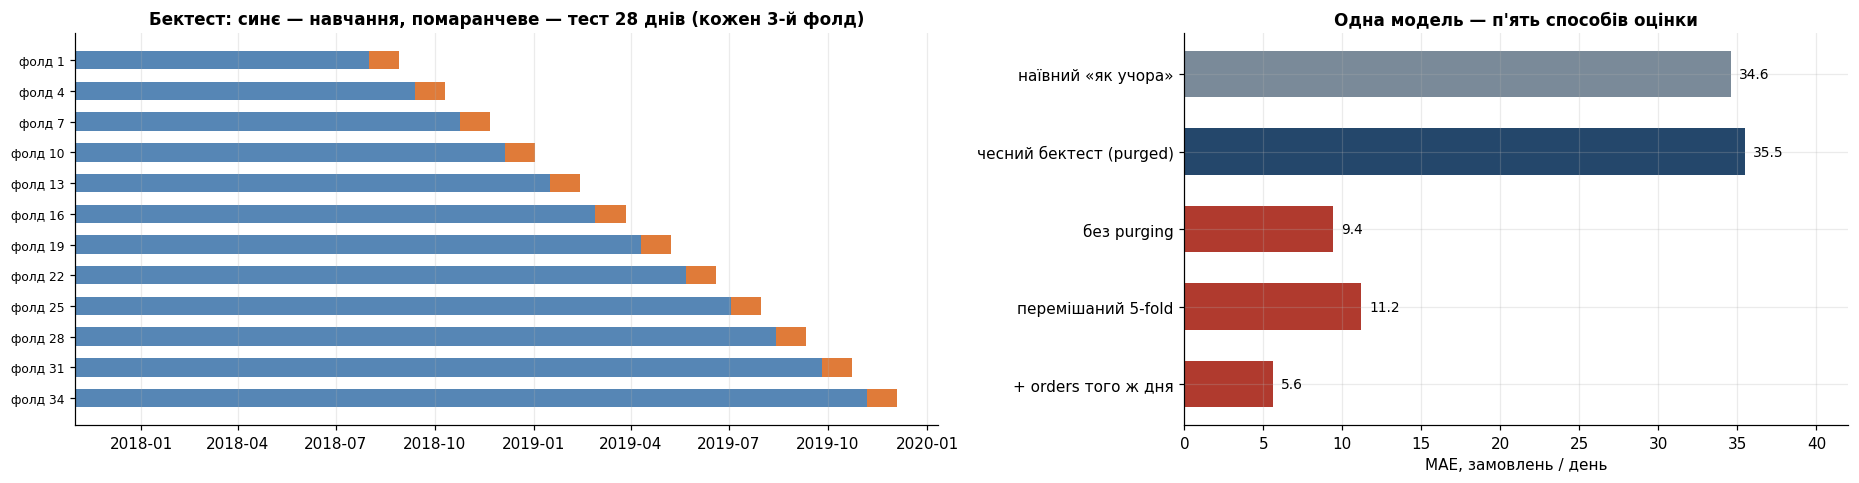

In [8]:
folds = pd.read_csv("folds_expanding.csv", parse_dates=["train_start", "train_end", "test_start", "test_end"])

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
shown = folds.iloc[::3]
for k, (_, r) in enumerate(shown.iterrows()):
    ax.barh(k, r["train_end"] - r["train_start"] + pd.Timedelta(days=1), left=r["train_start"], height=0.6, color=BLUE)
    ax.barh(k, pd.Timedelta(days=28), left=r["test_start"], height=0.6, color=ORANGE)
ax.set_yticks(range(len(shown))); ax.set_yticklabels([f"фолд {f}" for f in shown["fold"]], fontsize=8)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_title("Бектест: синє — навчання, помаранчеве — тест 28 днів (кожен 3-й фолд)")

# leakage experiment: same Random Forest, five ways to evaluate (results of eda.ipynb, section 2.4)
leak = pd.Series({
    "наївний «як учора»": 34.6,
    "чесний бектест (purged)": 35.5,
    "без purging": 9.4,
    "перемішаний 5-fold": 11.2,
    "+ orders того ж дня": 5.6,
})
ax = axes[1]
bars = ax.barh(leak.index, leak.values, color=[GREY, NAVY, RED, RED, RED], height=0.6)
for b, v in zip(bars, leak.values):
    ax.text(v + 0.5, b.get_y() + b.get_height() / 2, f"{v:.1f}", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, 42)
ax.set_xlabel("MAE, замовлень / день")
ax.set_title("Одна модель — п'ять способів оцінки")
plt.tight_layout(); plt.show()

- Чесна помилка Random Forest **35,5**, а з витоками вона виглядає як **5,6–11** — модель здається в 3–6 разів кращою, ніж є.
- Чесний результат неприємний: модель **не б'є наївний прогноз** (35,5 проти 34,6). Це точка відліку для розділу 3.
- Обмеження: пік літа 2018 лише в навчанні, усі тести — спокійніший період після серпня 2018.

# 3. Базові моделі та метрики

Усі моделі — на тих самих 35 фолдах. **MAE** (помилка в замовленнях/день), **RMSE** (сильніше карає великі промахи), **WAPE** (помилка у % від рівня), **bias** (зміщення; мінус = прогноз завищений), помилка **28-денної суми** (для запасів). MAPE не беремо — у ряді є нулі.

In [9]:
# backtest results of eda.ipynb, section 3.6 (35 folds x 28 days)
cols = ["MAE", "RMSE", "WAPE", "bias", "помилка 28-денної суми", "MAE h 1–7", "MAE h 8–14", "MAE h 15–28", "фолдів краще за наївний"]
comparison = pd.DataFrame([
    ["Holt–Winters weekly (log)",       29.84, 42.72, .376, -.021, .351, 18.69, 27.94, 36.36, 19],
    ["SARIMA (2,1,2)(1,0,1)7",          31.21, 42.80, .393, -.046, .361, 20.16, 28.82, 37.93, 17],
    ["Random Forest (rolling 273)",     31.28, 42.40, .394, -.054, .386, 20.87, 29.42, 37.42, 18],
    ["SARIMAX + події",                 31.42, 42.94, .396, -.074, .354, 21.37, 29.13, 37.59, 16],
    ["наївний «як учора»",              31.62, 45.17, .398, -.094, .377, 20.23, 29.79, 38.22, np.nan],
    ["SES (log)",                       31.79, 45.48, .400, -.099, .383, 20.39, 29.83, 38.47, 18],
    ["ковзне середнє 7",                32.16, 43.79, .405, -.050, .377, 21.59, 30.27, 38.39, 19],
    ["LightGBM (rolling 273)",          33.86, 44.76, .426, -.103, .418, 24.15, 32.39, 39.44, 13],
    ["сезонний наївний (тиждень тому)", 33.99, 46.46, .428, -.050, .377, 23.55, 33.17, 39.61, 16],
    ["Ridge",                           34.81, 44.25, .438, -.132, .449, 25.71, 32.69, 40.41, 14],
], columns=["модель"] + cols).set_index("модель")
comparison.insert(1, "Δ MAE до наївного", comparison["MAE"] / comparison.loc["наївний «як учора»", "MAE"] - 1)

def best(col):
    s = col.abs() if col.name == "bias" else col
    target = s.max() if col.name == "фолдів краще за наївний" else s.min()
    return ["background-color: #2F855A33; font-weight: bold" if v == target else "" for v in s]

display(comparison.style
        .apply(best, subset=[c for c in comparison.columns if c != "Δ MAE до наївного"])
        .format({"MAE": "{:.1f}", "RMSE": "{:.1f}", "WAPE": "{:.1%}", "bias": "{:+.1%}", "помилка 28-денної суми": "{:.1%}",
                 "MAE h 1–7": "{:.1f}", "MAE h 8–14": "{:.1f}", "MAE h 15–28": "{:.1f}",
                 "Δ MAE до наївного": "{:+.1%}", "фолдів краще за наївний": lambda v: "—" if pd.isna(v) else f"{int(v)} / 35"})
        .set_caption("Зелене — найкраще значення в колонці"))

,MAE,Δ MAE до наївного,RMSE,WAPE,bias,помилка 28-денної суми,MAE h 1–7,MAE h 8–14,MAE h 15–28,фолдів краще за наївний
модель,,,,,,,,,,
Holt–Winters weekly (log),29.8,-5.6%,42.7,37.6%,-2.1%,35.1%,18.7,27.9,36.4,19 / 35
"SARIMA (2,1,2)(1,0,1)7",31.2,-1.3%,42.8,39.3%,-4.6%,36.1%,20.2,28.8,37.9,17 / 35
Random Forest (rolling 273),31.3,-1.1%,42.4,39.4%,-5.4%,38.6%,20.9,29.4,37.4,18 / 35
SARIMAX + події,31.4,-0.6%,42.9,39.6%,-7.4%,35.4%,21.4,29.1,37.6,16 / 35
наївний «як учора»,31.6,+0.0%,45.2,39.8%,-9.4%,37.7%,20.2,29.8,38.2,—
SES (log),31.8,+0.5%,45.5,40.0%,-9.9%,38.3%,20.4,29.8,38.5,18 / 35
ковзне середнє 7,32.2,+1.7%,43.8,40.5%,-5.0%,37.7%,21.6,30.3,38.4,19 / 35
LightGBM (rolling 273),33.9,+7.1%,44.8,42.6%,-10.3%,41.8%,24.1,32.4,39.4,13 / 35
сезонний наївний (тиждень тому),34.0,+7.5%,46.5,42.8%,-5.0%,37.7%,23.6,33.2,39.6,16 / 35


Перераховано наживо на 35 фолдах: наївний MAE = 31.6, Holt–Winters (log) MAE = 29.8


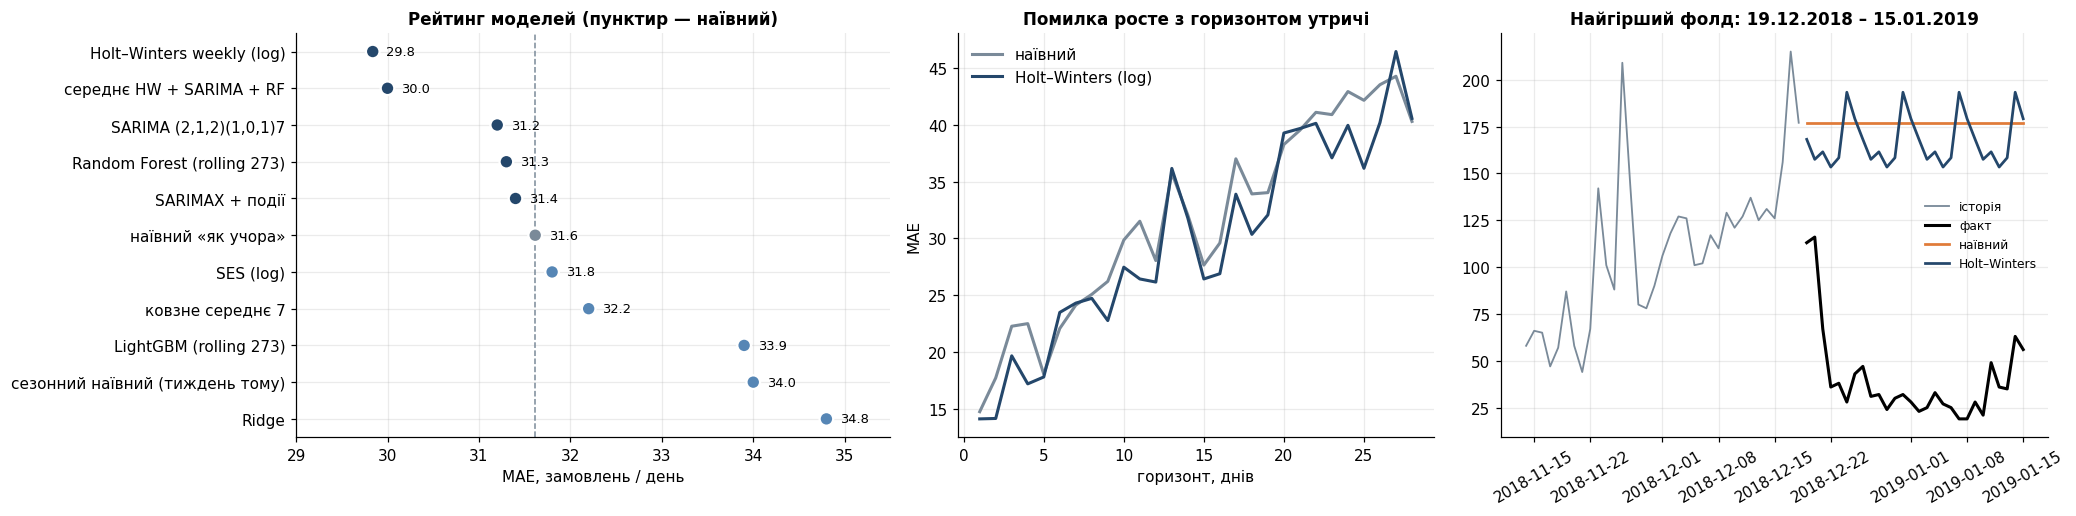

In [10]:
def run_backtest(forecast_fn):
    rows = []
    for _, r in folds.iterrows():
        dates = pd.date_range(r["test_start"], r["test_end"])
        rows.append(pd.DataFrame({"fold": r["fold"], "date": dates, "h": np.arange(1, 29),
                                  "y": ts.reindex(dates).values, "pred": forecast_fn(r["train_end"], dates)}))
    return pd.concat(rows, ignore_index=True)

def naive(te, dates):
    return np.repeat(ts.loc[te], len(dates))

def holt_winters(te, dates):
    s = ls.loc[:te].copy(); s.index.freq = "D"
    fit = ExponentialSmoothing(s, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7,
                               initialization_method="estimated").fit()
    return np.clip(np.expm1(fit.forecast(len(dates)).values), 0, None)

res = {"наївний": run_backtest(naive), "Holt–Winters (log)": run_backtest(holt_winters)}
mae = {k: (v["y"] - v["pred"]).abs().mean() for k, v in res.items()}
print("Перераховано наживо на 35 фолдах: " + ", ".join(f"{k} MAE = {v:.1f}" for k, v in mae.items()))

# MAE of all model families (eda.ipynb, section 3.6); naive and Holt-Winters are recomputed above
board = pd.Series({
    "Holt–Winters weekly (log)": mae["Holt–Winters (log)"],
    "середнє HW + SARIMA + RF": 30.0,
    "SARIMA (2,1,2)(1,0,1)7": 31.2,
    "Random Forest (rolling 273)": 31.3,
    "SARIMAX + події": 31.4,
    "наївний «як учора»": mae["наївний"],
    "SES (log)": 31.8,
    "ковзне середнє 7": 32.2,
    "LightGBM (rolling 273)": 33.9,
    "сезонний наївний (тиждень тому)": 34.0,
    "Ridge": 34.8,
})
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), gridspec_kw={"width_ratios": [1.25, 1, 1.15]})
ax = axes[0]
colors = [NAVY if v < mae["наївний"] - 0.05 else (GREY if "наївний «" in k else BLUE) for k, v in board.items()]
yy = np.arange(len(board))
ax.scatter(board.values, yy, s=80, color=colors, edgecolor="white", linewidth=1.5, zorder=3)
for y_, v in zip(yy, board.values):
    ax.text(v + 0.15, y_, f"{v:.1f}", va="center", fontsize=8.5)
ax.set_yticks(yy); ax.set_yticklabels(board.index)
ax.axvline(mae["наївний"], color=GREY, linestyle="--", linewidth=1)
ax.set_xlim(29, 35.5); ax.invert_yaxis()
ax.set_xlabel("MAE, замовлень / день")
ax.set_title("Рейтинг моделей (пунктир — наївний)")

ax = axes[1]
for (name, d), c in zip(res.items(), [GREY, NAVY]):
    (d["y"] - d["pred"]).abs().groupby(d["h"]).mean().plot(ax=ax, color=c, linewidth=2, label=name)
ax.set_xlabel("горизонт, днів"); ax.set_ylabel("MAE")
ax.set_title("Помилка росте з горизонтом утричі"); ax.legend()

ax = axes[2]
r = folds.set_index("fold").loc[11]
hist = ts.loc[r["test_start"] - pd.Timedelta(days=35):r["train_end"]]
ax.plot(hist.index, hist, color=GREY, linewidth=1.2, label="історія")
d = res["наївний"]; d = d[d["fold"] == 11]
ax.plot(d["date"], d["y"], color="black", linewidth=2, label="факт")
ax.plot(d["date"], d["pred"], color=ORANGE, linewidth=1.8, label="наївний")
d = res["Holt–Winters (log)"]; d = d[d["fold"] == 11]
ax.plot(d["date"], d["pred"], color=NAVY, linewidth=1.8, label="Holt–Winters")
ax.tick_params(axis="x", rotation=30); ax.legend(fontsize=8)
ax.set_title("Найгірший фолд: 19.12.2018 – 15.01.2019")
plt.tight_layout(); plt.show()

- **Найкраща — Holt–Winters на log(1+y): MAE 29,8, на 5,6% краще за наївний** (31,6). Але краща лише на 19 з 35 фолдів.
- SARIMA, Random Forest, LightGBM, Ridge **наївний прогноз помітно не б'ють**; усереднення моделей майже нічого не дає — вони помиляються на тих самих фолдах.
- Помилка: **≈ 15 на 1-й день → ≈ 40–45 на 28-й**; помилка місячної суми **35–39%**.
- Найбільші промахи — **різкі зміни рівня** (порожній FBA, свята): на фолді 11 продажі падають зі ~175 до ~35, а жодна модель цього не бачить, бо ознак на момент прогнозу немає.

**Висновок:** прості моделі дають невеликий виграш, складні — нічого. Для оптимізації прогноз треба брати з інтервалом або сценаріями.

# 4. Місток до оптимізації

Прогноз потрібен, щоб вирішити, **скільки товару і на який склад Amazon відправляти**.

## 4.1 Звідки приходять замовлення

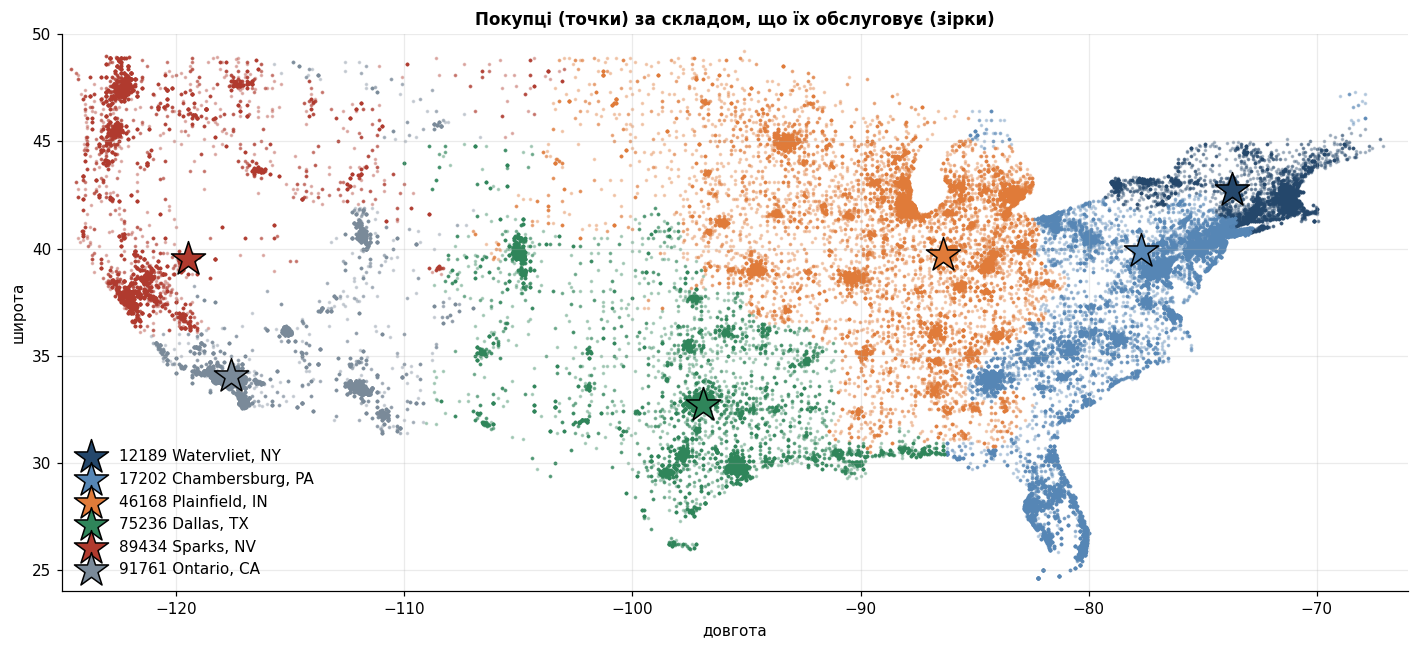

year,склад,"2017, %","2018, %","2019, %"
warehouse_zip,,,,
12189,"Watervliet, NY",6.0,6.4,6.5
17202,"Chambersburg, PA",28.7,27.0,30.4
46168,"Plainfield, IN",24.4,22.3,23.3
75236,"Dallas, TX",13.8,15.2,14.0
89434,"Sparks, NV",12.0,13.6,12.9
91761,"Ontario, CA",13.0,13.5,12.7
99999,"поза складами (HI, AK, PR)",2.0,2.0,0.3


In [11]:
WAREHOUSES = {12189: ("Watervliet, NY", 42.73, -73.72), 17202: ("Chambersburg, PA", 39.90, -77.70),
              46168: ("Plainfield, IN", 39.68, -86.40), 75236: ("Dallas, TX", 32.69, -96.92),
              89434: ("Sparks, NV", 39.50, -119.50), 91761: ("Ontario, CA", 34.03, -117.59)}
WH_COLORS = [NAVY, BLUE, ORANGE, GREEN, RED, GREY]

fig, ax = plt.subplots(figsize=(13, 6))
for (z, (name, lat, lon)), c in zip(WAREHOUSES.items(), WH_COLORS):
    cust = orders[orders["warehouse_zip"] == z].dropna(subset=["lat"])
    ax.scatter(cust["long"], cust["lat"], s=2, alpha=0.3, color=c)
    ax.scatter(lon, lat, marker="*", s=550, color=c, edgecolor="black", zorder=5, label=f"{z} {name}")
ax.set_xlim(-125, -66); ax.set_ylim(24, 50)
ax.set_xlabel("довгота"); ax.set_ylabel("широта")
ax.set_title("Покупці (точки) за складом, що їх обслуговує (зірки)")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

shares = (orders[orders.date.dt.year < 2020].assign(year=orders.date.dt.year)
          .pivot_table(index="warehouse_zip", columns="year", values="count", aggfunc="size")
          .pipe(lambda t: t / t.sum() * 100))
shares.insert(0, "склад", [WAREHOUSES[z][0] if z in WAREHOUSES else "поза складами (HI, AK, PR)" for z in shares.index])
display(shares.round(1).rename(columns={2017: "2017, %", 2018: "2018, %", 2019: "2019, %"}))

- 6 складів ділять США на зони; найбільші — **Пенсильванія (~28%)** та **Індіана (~23%)**, найменший — Нью-Йорк (~6%).
- **Частки складів стабільні рік до року** → попит складу = загальний прогноз × частка складу.

## 4.2 Постановка оптимізаційної задачі

```
постачальник ──(платить продавець, L днів)──► 6 складів Amazon ──(доставляє Amazon)──► покупці свого регіону
```

**Змінні рішення:** $x_{w,t}$ — скільки штук відправити на склад $w$ у період $t$ (напр., раз на 2 тижні).

**Цільова функція** — мінімізувати витрати на зберігання і доставку на склади
(доставку покупцю Amazon бере фіксовано за штуку, від складу не залежить, тому її немає):

$$
\min_{x}\; \sum_{t}\sum_{w}\Big(h \cdot I_{w,t} + c_w \cdot x_{w,t}\Big)
$$

**Обмеження**

| | Формула | Зміст |
|---|---|---|
| баланс запасу | $I_{w,t} = I_{w,t-1} + x_{w,t-L} - D_{w,t}$ | було + приїхало − продали |
| покриття попиту | $I_{w,t} \ge 0$ | без дефіциту (інакше оптимум — нічого не везти) |
| місткість | $I_{w,t} \le \text{cap}_w$ | ліміт складу |
| невід'ємність | $x_{w,t} \ge 0$ | |

**Попит з прогнозу:**
$\;D_{w,t} = \underbrace{\text{прогноз замовлень}_t}_{\text{модель}} \times \underbrace{\text{штук на замовлення}}_{\text{orders}} \times \underbrace{\text{частка складу } w}_{\text{4.1}}$

Прогноз замовлень на 28 днів: 1,432, факт 2,949 (прогноз нижчий у 2.1 раза); штук на замовлення: 1.01


,частка,частка факт,"прогноз, шт.","верхній сценарій +35%, шт.","факт, шт."
"Chambersburg, PA",30.4%,31.7%,441,595,944
"Plainfield, IN",23.1%,27.8%,336,453,827
"Dallas, TX",15.5%,14.3%,226,305,424
"Ontario, CA",13.5%,9.7%,196,265,289
"Sparks, NV",12.1%,9.1%,175,237,271
"Watervliet, NY",5.3%,7.4%,77,104,220
РАЗОМ,100.0%,100.0%,"1,451","1,959","2,975"


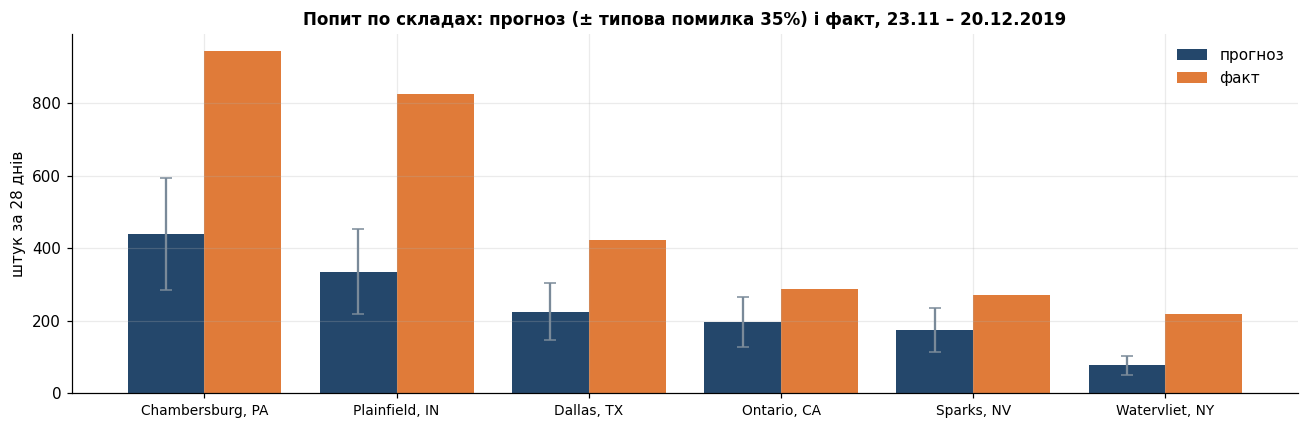

In [12]:
ORIGIN, H = pd.Timestamp("2019-11-22"), 28
s = ls.loc[:ORIGIN].copy(); s.index.freq = "D"
hw = ExponentialSmoothing(s, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7,
                          initialization_method="estimated").fit()
fc_orders = np.expm1(hw.forecast(H)).clip(0).sum()
period = (orders.date > ORIGIN) & (orders.date <= ORIGIN + pd.Timedelta(days=H))
recent = (orders.date > ORIGIN - pd.Timedelta(days=90)) & (orders.date <= ORIGIN)
units_per_order = orders.loc[recent, "count"].mean()
wh_share = orders.loc[recent, "warehouse_zip"].value_counts(normalize=True)

ERR = 0.35  # typical error of the 28-day total in backtest (35-39%)
demand = pd.DataFrame({"частка": wh_share})
demand["прогноз, шт."] = fc_orders * units_per_order * demand["частка"]
demand["верхній сценарій +35%, шт."] = demand["прогноз, шт."] * (1 + ERR)
demand["факт, шт."] = orders.loc[period].groupby("warehouse_zip")["count"].sum().reindex(demand.index).fillna(0)
demand["частка факт"] = demand["факт, шт."] / demand["факт, шт."].sum()
demand.index = [WAREHOUSES[z][0] if z in WAREHOUSES else "поза складами" for z in demand.index]
demand = demand[demand["факт, шт."] + demand["прогноз, шт."] >= 1]
demand.loc["РАЗОМ"] = demand.sum()

fact_orders = ts.loc[ORIGIN + pd.Timedelta(days=1):ORIGIN + pd.Timedelta(days=H)].sum()
print(f"Прогноз замовлень на 28 днів: {fc_orders:,.0f}, факт {fact_orders:,.0f} (прогноз нижчий у {fact_orders / fc_orders:.1f} раза); "
      f"штук на замовлення: {units_per_order:.2f}")
display(demand[["частка", "частка факт", "прогноз, шт.", "верхній сценарій +35%, шт.", "факт, шт."]].style.format(
    {"частка": "{:.1%}", "частка факт": "{:.1%}", "прогноз, шт.": "{:,.0f}", "верхній сценарій +35%, шт.": "{:,.0f}", "факт, шт.": "{:,.0f}"}))

d = demand.drop(index=["РАЗОМ", "поза складами"], errors="ignore")
x = np.arange(len(d))
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(x - 0.2, d["прогноз, шт."], width=0.4, color=NAVY, label="прогноз",
       yerr=[d["прогноз, шт."] * ERR, d["прогноз, шт."] * ERR], capsize=4, ecolor=GREY)
ax.bar(x + 0.2, d["факт, шт."], width=0.4, color=ORANGE, label="факт")
ax.set_xticks(x); ax.set_xticklabels(d.index, rotation=0, fontsize=9)
ax.set_ylabel("штук за 28 днів")
ax.set_title("Попит по складах: прогноз (± типова помилка 35%) і факт, 23.11 – 20.12.2019")
ax.legend()
plt.tight_layout(); plt.show()

## 4.3 Поточні обмеження

| Елемент задачі | Позначення | Чи є в даних |
|---|---|---|
| Прогноз попиту (замовлення) | $D_t$ | ✅ модель (Holt–Winters, MAE 29,8) |
| Штук на замовлення | — | ✅ `orders.count` (змінюється ≈ 2 → ≈ 1) |
| Частки складів | — | ✅ `orders.warehouse_zip`, стабільні |
| Поточний запас по складах | $I_{w,0}$ | ❌ лише сумарний FBA, нормований 0–1, без штук |
| Вартість зберігання | $h$ | ❌ |
| Вартість доставки на склад | $c_w$ | ❌ немає тарифів і розташування постачальника |
| Час поставки | $L$ | ❌ |
| Місткість складу | $\text{cap}_w$ | ❌ |
| Справжній попит у дні без товару | — | ❌ бачимо продажі, а не попит → прогноз занижений |
| Невизначеність прогнозу | — | ⚠️ помилка 28-денної суми 35–39%, моделі дають лише точковий прогноз |

**Задачу сформулювати можна** (попит і його розподіл по складах є), **розв'язати з реальними числами — поки ні**: витрати, час поставки, місткість і запаси по складах треба отримати від бізнесу або задати як припущення.

# Висновки та наступні кроки

### Висновки
1. **`target` — кількість замовлень за день** (= рядки `orders`, кореляція 0,999); штук у замовленні з часом поменшало (≈ 2 → ≈ 1).
2. Товар пройшов повний життєвий цикл; для моделювання взято **стабільне вікно 780 днів (99,2% продажів)**.
3. **Головний чинник продажів — наявність товару на FBA**: порожній склад у 41% днів, 85% провалів припадає саме на них → у ці дні бачимо продажі, а не попит.
4. Ряд з **сильною інерцією і трендом**, **слабкою, але стабільною тижневою** сезонністю і **нестійкою річною**.
5. Аномалії й заглушки (NaN target, ціна 422,78 $, нулі пошукових позицій) **знайдено й позначено, а не видалено**.
6. Найкраща модель (Holt–Winters на log) лише **на 5,6% краща за наївну**; помилка 28-денної суми **35–39%**.
7. **Задачу розподілу запасу по 6 складах сформульовано**; бракує економічних параметрів.

### Наступні кроки
**Прогноз**
- додати екзогенні фактори: температура в регіонах, Google Trends, дати Prime Day / Black Friday;
- інтервальний прогноз → страховий запас під рівень сервісу (напр., 95%);
- прогнозувати одразу в штуках.

**Оптимізація**
- знайти у відкритих джерелах тарифи Amazon FBA ($h$), доставку на склади ($c_w$), час поставки ($L$), ліміти ($\text{cap}_w$);
- **якщо знайдено** → розв'язати задачу розподілу запасу і перевірити на бектесті;
- **якщо ні** → сценарії параметрів (низькі / базові / високі витрати) і чутливість рішення до них.